In [12]:
# 3. Clustering the Word2Vec vocabulary

from difflib import SequenceMatcher
from pathlib import Path

from adjustText import adjust_text
from gensim.models import Word2Vec
import hdbscan
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import umap

DATA = Path("../data")   # not included in the repository, contact the author
TAB = Path("../tab")
FIG = Path("../fig")

UMAP_PARAMS = dict(n_neighbors=30, min_dist=0.0, n_components=2, random_state=42)
HDBSCAN_PARAMS = dict(min_cluster_size=50, min_samples=10)

w2v = Word2Vec.load(str(DATA / "models" / "word2vec.model"))
words = w2v.wv.index_to_key
index = {w: i for i, w in enumerate(words)}

In [13]:
# Definitions

# Seed forms of the variant list: five noise terms, their "nacht-" compounds, and "nachtrust".
SEEDS = ["lawijd", "lawaai", "gerucht", "kabaal", "rumoer",
         "nachtlawijd", "nachtlawaai", "nachtrumoer", "nachtgerucht", "nachtrust"]


# Spelling and HTR variants of the five core terms, selected manually from the FastText
# neighbours. Used for term frequencies and for the semantic field (Appendix A).
TERM_VARIANTS = {
    "lawijd": ["lawijd", "lawijdt", "lawijt", "lawit", "lawid", "lawyjd", "lawyt", "lewijd", "lawyd"],
    "nachtlawijd": ["nachtlawijd", "nachtlawijt", "nachtlawyd"],
    "lawaai": ["lawaai", "lawaar"],
    "nachtlawaai": ["nachtlawaai", "nachtlangd"],
    "rumoer": ["rumoer", "ramoer", "zamoer"],
    "nachtrumoer": ["nachtrumoer", "nachtramoer", "nachtrumaer"],
    "gerucht": ["gerucht", "gerugt", "gercht"],
    "nachtgerucht": ["nachtgerucht"],
    "kabaal": ["kabaal", "habaal"],
    "nachtkabaal": ["nachtkabaal"],
}


CORE_TERMS = ["lawijd", "gerucht", "rumoer", "kabaal", "lawaai"]


def term_group(term):
    """All variants of a core term, including its "nacht-" compound."""
    return TERM_VARIANTS[term] + TERM_VARIANTS["nacht" + term]

In [14]:
# Clustering

xy = umap.UMAP(**UMAP_PARAMS).fit_transform(w2v.wv[words])
hdb = hdbscan.HDBSCAN(**HDBSCAN_PARAMS, gen_min_span_tree=True).fit(xy)
labels = hdb.labels_

clusters = pd.DataFrame({"word": words, "cluster": labels,
                         "freq": [w2v.wv.get_vecattr(w, "count") for w in words]})
clusters.to_csv(TAB / "word2vec_clusters.csv", index=False)

print(f"{len(words):,} words | {labels.max() + 1} clusters | "
      f"{(labels >= 0).sum():,} clustered ({(labels >= 0).mean():.1%}) | DBCV {hdb.relative_validity_:.3f}")

/opt/anaconda3/envs/incidentbooks/lib/python3.11/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


30,468 words | 97 clusters | 16,886 clustered (55.4%) | DBCV 0.286


In [15]:
# Clusters of interest, identified by one of their members, with their 25 most frequent words.

def cluster_of(word):
    return int(labels[index[word]])

def describe(word, n=25):
    c = cluster_of(word)
    members = clusters[clusters["cluster"] == c].nlargest(n, "freq")["word"]
    print(f"cluster {c} ({(labels == c).sum()} words), via '{word}':\n  {', '.join(members)}\n")

for word in ["nachtrust", "kabaal", "gerucht", "tapage", "bellen"]:   # noise, verbal conflict, inns, French, ringing
    describe(word)

cluster 27 (112 words), via 'nachtrust':
  roepen, rust, inwoners, nachtrust, aard, stoorde, luidkeels, zingen, geburen, straten, storen, twisten, tieren, inwooners, luid, omliggende, stooren, gestoord, lawijd, aand, schreeuwen, stoorden, lawijt, lawaai, nachtgerucht

cluster 72 (339 words), via 'kabaal':
  gij, zeggende, hebt, begon, antwoorde, riep, woorden, dief, zijt, antwoordde, uwe, smeerlap, hoer, gy, zit, zaken, kunt, zeg, beleedigd, beter, wilt, uwen, affaire, zult, kalmte

cluster 21 (134 words), via 'gerucht':
  herberg, cafe, gehouden, drank, publiek, verbruikers, lokaal, muziek, dansen, gerucht, houder, houdster, geluid, orgel, verbruiker, koppels, uitbater, herber, dienster, bafe, herbergier, toegankelijk, gespeeld, gezongen, bediend

cluster 96 (505 words), via 'tapage':
  que, les, qu, qui, etait, nous, avait, elle, maison, cette, avons, chez, avec, etant, mais, devant, sont, plus, ils, meme, ces, suis, deux, service, depuis

cluster 36 (90 words), via 'bellen':
  voorb

In [16]:
noise = cluster_of("nachtrust")
print("seed forms in the noise cluster:", [s for s in SEEDS if cluster_of(s) == noise])
print("seed forms elsewhere:", {s: cluster_of(s) for s in SEEDS if cluster_of(s) != noise})
for word in ["krakeel", "twisten", "tierde", "luidruchtig", "ruzie", "bruit"]:
    print(f"{word:<12} cluster {cluster_of(word)}")

seed forms in the noise cluster: ['lawijd', 'lawaai', 'rumoer', 'nachtlawijd', 'nachtlawaai', 'nachtrumoer', 'nachtgerucht', 'nachtrust']
seed forms elsewhere: {'gerucht': 21, 'kabaal': 72}
krakeel      cluster 27
twisten      cluster 27
tierde       cluster 27
luidruchtig  cluster 27
ruzie        cluster -1
bruit        cluster 96


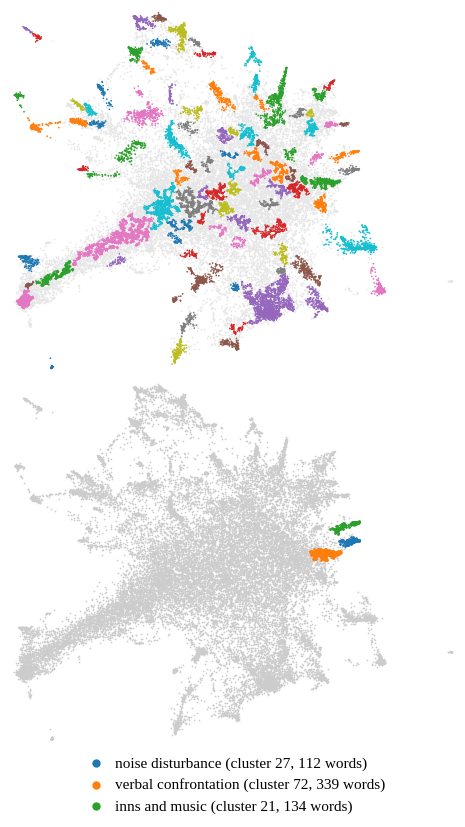

In [25]:
# Figure 3
from matplotlib import font_manager

for font in (Path("../../fonts/Tinos")).glob("*.ttf"):
    font_manager.fontManager.addfont(str(font))
plt.rcParams.update({"font.family": "serif", "font.serif": ["Tinos", "Times New Roman", "DejaVu Serif"],
                     "font.size": 11})

TEXT_WIDTH, FIG_HEIGHT = 426.8 / 72, 590 / 72   # inches; leaves room for the caption
HIGHLIGHT = {cluster_of("nachtrust"): ("noise disturbance", "#1f77b4"),
             cluster_of("kabaal"): ("verbal confrontation", "#ff7f0e"),
             cluster_of("gerucht"): ("inns and music", "#2ca02c")}

# UMAP orientation is arbitrary: rotate the projection so that its longest axis is horizontal
# (a pure rotation, distances and clusters are unchanged), so that it fills the text width.
ROTATE = True
xy_plot = xy - xy.mean(axis=0)
if ROTATE:
    _, _, axes = np.linalg.svd(xy_plot, full_matrices=False)
    if np.linalg.det(axes) < 0:   # keep it a rotation, not a mirror image
        axes[1] *= -1
    xy_plot = xy_plot @ axes.T

fig, (top, bottom) = plt.subplots(2, 1, figsize=(TEXT_WIDTH, FIG_HEIGHT), layout="constrained",
                                 sharex=True, sharey=True)   # identical shape for both panels
clustered = labels >= 0
top.scatter(xy_plot[~clustered, 0], xy_plot[~clustered, 1], s=1.5, color="#e6e6e6", linewidth=0)
top.scatter(xy_plot[clustered, 0], xy_plot[clustered, 1], s=1.5, c=labels[clustered] % 10, cmap="tab10", linewidth=0)
bottom.scatter(xy_plot[:, 0], xy_plot[:, 1], s=1.5, color="#cccccc", linewidth=0)
for cluster, (name, colour) in HIGHLIGHT.items():
    part = labels == cluster
    bottom.scatter(xy_plot[part, 0], xy_plot[part, 1], s=4, color=colour, linewidth=0,
                   label=f"{name} (cluster {cluster}, {part.sum()} words)")
for ax in (top, bottom):
    ax.margins(0.01)
    ax.set_aspect("equal")   # no stretching
    ax.set_axis_off()
fig.legend(frameon=False, loc="outside lower center", ncol=1, markerscale=3, handletextpad=0.2)
for ext in ("png", "pdf"):
    fig.savefig(FIG / f"hdbscan_clusters.{ext}", dpi=300)

In [18]:
# Sensitivity to the HDBSCAN parameters

rows = []
for mcs in [10, 25, 50, 75, 100, 150]:
    for ms in [5, 10, 25]:
        h = hdbscan.HDBSCAN(min_cluster_size=mcs, min_samples=ms, gen_min_span_tree=True).fit(xy)
        lab, c = h.labels_, h.labels_[index["nachtrust"]]
        inside = [s for s in SEEDS if c >= 0 and lab[index[s]] == c]
        rows.append({"min_cluster_size": mcs, "min_samples": ms, "clusters": lab.max() + 1,
                     "clustered_pct": round((lab >= 0).mean() * 100, 1), "dbcv": round(h.relative_validity_, 3),
                     "noise_cluster_size": int((lab == c).sum()) if c >= 0 else 0,
                     "seeds_in_noise_cluster": len(inside),
                     "seeds_outside": ", ".join(s for s in SEEDS if s not in inside)})
sensitivity = pd.DataFrame(rows)
sensitivity.to_csv(TAB / "hdbscan_sensitivity.csv", index=False)
sensitivity

,min_cluster_size,min_samples,clusters,clustered_pct,dbcv,noise_cluster_size,seeds_in_noise_cluster,seeds_outside
0,10,5,538,58.9,0.184,71,5,"lawijd, lawaai, gerucht, kabaal, rumoer"
1,10,10,349,52.7,0.181,112,8,"gerucht, kabaal"
2,10,25,151,52.9,0.219,105,8,"gerucht, kabaal"
3,25,5,215,62.8,0.216,113,8,"gerucht, kabaal"
4,25,10,173,55.0,0.241,112,8,"gerucht, kabaal"
5,25,25,76,74.9,0.109,105,8,"gerucht, kabaal"
6,50,5,115,61.1,0.232,113,8,"gerucht, kabaal"
7,50,10,97,55.4,0.286,112,8,"gerucht, kabaal"
8,50,25,59,76.8,0.163,105,8,"gerucht, kabaal"
9,75,5,75,57.9,0.295,113,8,"gerucht, kabaal"


In [19]:
# Appendix A: semantic field of the five core terms

groups = {t: [w for w in term_group(t) if w in w2v.wv] for t in CORE_TERMS}
field, group_of = [], {}
for term, variants in groups.items():
    centre = np.mean([w2v.wv[w] for w in variants], axis=0)
    neighbours = [w for w, _ in w2v.wv.similar_by_vector(centre, topn=100) if w not in variants]
    for w in variants:
        group_of.setdefault(w, term)
    field += [w for w in variants + neighbours if w not in field]

pos = umap.UMAP(random_state=42).fit_transform(w2v.wv[field])
field = pd.DataFrame({"word": field, "x": pos[:, 0], "y": pos[:, 1],
                      "freq": [w2v.wv.get_vecattr(w, "count") for w in field],
                      "group": [group_of.get(w) for w in field]})

/opt/anaconda3/envs/incidentbooks/lib/python3.11/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


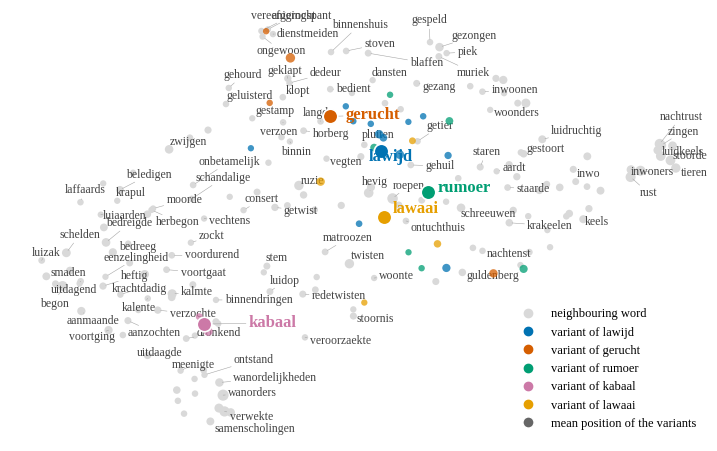

In [20]:
def same_lemma(a, b):
    a, b = a.replace("y", "ij"), b.replace("y", "ij")
    return SequenceMatcher(None, a, b).ratio() >= 0.8

# Printed on a landscape page: the figure is drawn at its final size, in the paper's typeface (Tinos).
from matplotlib import font_manager
from matplotlib.lines import Line2D

for font in (Path("../../fonts/Tinos")).glob("*.ttf"):
    font_manager.fontManager.addfont(str(font))
plt.rcParams.update({"font.family": "serif", "font.serif": ["Tinos", "Times New Roman", "DejaVu Serif"]})

COLOURS = dict(zip(CORE_TERMS, ["#0072B2", "#D55E00", "#009E73", "#CC79A7", "#E69F00"]))
size = 4 + np.log1p(field["freq"]) / np.log1p(field["freq"]).max() * 60

fig, ax = plt.subplots(figsize=(9, 5.6))
neighbours = field[field["group"].isna()].sort_values("freq", ascending=False)
ax.scatter(neighbours["x"], neighbours["y"], s=size[neighbours.index], color="#d9d9d9", linewidth=0, zorder=1)

texts, lemmas = [], []
for _, r in neighbours.iterrows():           # one label per neighbour, not per spelling variant
    if not any(same_lemma(r["word"], l) for l in lemmas):
        lemmas.append(r["word"])
        texts.append(ax.text(r["x"], r["y"], r["word"], fontsize=8.5, color="#444444", zorder=2))

for term, colour in COLOURS.items():
    part = field[field["group"] == term]
    ax.scatter(part["x"], part["y"], s=size[part.index], color=colour, alpha=0.75, linewidth=0, zorder=3)
    x, y = part["x"].mean(), part["y"].mean()
    ax.scatter(x, y, s=110, color=colour, edgecolor="white", linewidth=1.2, zorder=4)
    texts.append(ax.text(x, y, term, fontsize=12, fontweight="bold", color=colour, zorder=5))

adjust_text(texts, ax=ax, expand=(1.15, 1.3), arrowprops=dict(arrowstyle="-", color="0.65", lw=0.4))

handles = [Line2D([], [], marker="o", linestyle="", markersize=6, color="#d9d9d9", label="neighbouring word")]
handles += [Line2D([], [], marker="o", linestyle="", markersize=6, color=c, label=f"variant of {t}")
            for t, c in COLOURS.items()]
handles += [Line2D([], [], marker="o", linestyle="", markersize=8, color="0.4", markeredgecolor="white",
                   label="mean position of the variants")]
ax.legend(handles=handles, loc="lower right", frameon=False, fontsize=9)
ax.axis("off")
for ext in ("png", "pdf"):
    fig.savefig(FIG / f"appendix_a_semantic_field.{ext}", dpi=300, bbox_inches="tight")